In [1]:
import pandas as pd
import numpy as np
import time

weekly_df = pd.read_csv(
    r"C:\Users\niran\Downloads\Drought prediction_ML\processed_weekly.csv",
    parse_dates=["date"]
)

print("Original shape:", weekly_df.shape)
print("Date range:",
      weekly_df["date"].min(),
      "->",
      weekly_df["date"].max())

Original shape: (278384, 89)
Date range: 2000-01-04 00:00:00 -> 2020-12-29 00:00:00


In [2]:
feature_cols = [

    # Current drought
    "score",
    "neighbor_score",

    # Rainfall
    "PRECTOT_mean_7d",
    "PRECTOT_mean_30d",
    "neighbor_PRECTOT_mean_7d",
    "neighbor_PRECTOT_mean_30d",

    # Temperature
    "T2M_mean_30d",
    "neighbor_T2M_mean_30d",

    # Humidity
    "QV2M_mean_30d",
    "neighbor_QV2M_mean_30d",

    # Wind
    "WS10M_mean_30d",
    "neighbor_WS10M_mean_30d",

    # Calendar
    "month_sin",
    "month_cos",
    "day_sin",
    "day_cos",

    # Soil
    "CULT_LAND",
    "SQ1",
    "SQ2",
    "SQ3",
    "SQ4",
    "SQ5",
    "SQ6",
    "SQ7"
]

print("Number of features:", len(feature_cols))

Number of features: 24


In [3]:
for h in [1, 2, 3, 4]:

    target = f"target_{h}w"

    if target not in weekly_df.columns:

        weekly_df[target] = (
            weekly_df
            .groupby("fips")["score"]
            .shift(-h)
        )

In [4]:
train_df = weekly_df[
    weekly_df["date"].dt.year <= 2014
].copy()

val_df = weekly_df[
    weekly_df["date"].dt.year.between(2015, 2017)
].copy()

test_df = weekly_df[
    weekly_df["date"].dt.year >= 2018
].copy()

print("=" * 70)
print("YEAR-BASED SPLIT")
print("=" * 70)

print(
    "TRAIN:",
    train_df["date"].min(),
    "->",
    train_df["date"].max(),
    train_df.shape
)

print(
    "VALIDATION:",
    val_df["date"].min(),
    "->",
    val_df["date"].max(),
    val_df.shape
)

print(
    "TEST:",
    test_df["date"].min(),
    "->",
    test_df["date"].max(),
    test_df.shape
)

YEAR-BASED SPLIT
TRAIN: 2000-01-04 00:00:00 -> 2014-12-30 00:00:00 (198882, 89)
VALIDATION: 2015-01-06 00:00:00 -> 2017-12-26 00:00:00 (39624, 89)
TEST: 2018-01-02 00:00:00 -> 2020-12-29 00:00:00 (39878, 89)


In [7]:
datasets = {}

for h in [1, 2, 3, 4]:

    target = f"target_{h}w"

    # Only remove NA for this particular target
    train = train_df.dropna(
        subset=[target] + feature_cols
    ).copy()

    val = val_df.dropna(
        subset=[target] + feature_cols
    ).copy()

    test = test_df.dropna(
        subset=[target] + feature_cols
    ).copy()


    datasets[h] = {

        "X_train": train[feature_cols],
        "y_train": train[target].astype(int),

        "X_val": val[feature_cols],
        "y_val": val[target].astype(int),

        "X_test": test[feature_cols],
        "y_test": test[target].astype(int)
    }


    print("\n" + "=" * 70)
    print(f"{h}-WEEK DATASET")
    print("=" * 70)

    print(
        "Train:",
        datasets[h]["X_train"].shape,
        datasets[h]["y_train"].shape
    )

    print(
        "Validation:",
        datasets[h]["X_val"].shape,
        datasets[h]["y_val"].shape
    )

    print(
        "Test:",
        datasets[h]["X_test"].shape,
        datasets[h]["y_test"].shape
    )


1-WEEK DATASET
Train: (198882, 24) (198882,)
Validation: (39624, 24) (39624,)
Test: (39624, 24) (39624,)

2-WEEK DATASET
Train: (198882, 24) (198882,)
Validation: (39624, 24) (39624,)
Test: (39370, 24) (39370,)

3-WEEK DATASET
Train: (198882, 24) (198882,)
Validation: (39624, 24) (39624,)
Test: (39116, 24) (39116,)

4-WEEK DATASET
Train: (198882, 24) (198882,)
Validation: (39624, 24) (39624,)
Test: (38862, 24) (38862,)


In [8]:
print("FEATURES BEING USED:")
print(feature_cols)

print("\nNumber of features:", len(feature_cols))

print("\nData types:")
print(
    datasets[4]["X_train"].dtypes
)

FEATURES BEING USED:
['score', 'neighbor_score', 'PRECTOT_mean_7d', 'PRECTOT_mean_30d', 'neighbor_PRECTOT_mean_7d', 'neighbor_PRECTOT_mean_30d', 'T2M_mean_30d', 'neighbor_T2M_mean_30d', 'QV2M_mean_30d', 'neighbor_QV2M_mean_30d', 'WS10M_mean_30d', 'neighbor_WS10M_mean_30d', 'month_sin', 'month_cos', 'day_sin', 'day_cos', 'CULT_LAND', 'SQ1', 'SQ2', 'SQ3', 'SQ4', 'SQ5', 'SQ6', 'SQ7']

Number of features: 24

Data types:
score                        float64
neighbor_score               float64
PRECTOT_mean_7d              float64
PRECTOT_mean_30d             float64
neighbor_PRECTOT_mean_7d     float64
neighbor_PRECTOT_mean_30d    float64
T2M_mean_30d                 float64
neighbor_T2M_mean_30d        float64
QV2M_mean_30d                float64
neighbor_QV2M_mean_30d       float64
WS10M_mean_30d               float64
neighbor_WS10M_mean_30d      float64
month_sin                    float64
month_cos                    float64
day_sin                      float64
day_cos                 

In [27]:
# ============================================================
# 1-WEEK DROUGHT CLASS DISTRIBUTION
# TRAINING vs TEST DATA
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Get 1-week data
# ------------------------------------------------------------

y_train = datasets[1]["y_train"].astype(int)
y_test = datasets[1]["y_test"].astype(int)

classes = [0, 1, 2, 3, 4, 5]

class_names = [
    "No Drought",
    "D0",
    "D1",
    "D2",
    "D3",
    "D4"
]

# ------------------------------------------------------------
# Count each class
# ------------------------------------------------------------

train_counts = y_train.value_counts().reindex(
    classes,
    fill_value=0
)

test_counts = y_test.value_counts().reindex(
    classes,
    fill_value=0
)

# ------------------------------------------------------------
# Create table
# ------------------------------------------------------------

distribution = pd.DataFrame({
    "Class": class_names,
    "Training Count": train_counts.values,
    "Test Count": test_counts.values
})

# Percentages
distribution["Training %"] = (
    distribution["Training Count"]
    / distribution["Training Count"].sum()
    * 100
)

distribution["Test %"] = (
    distribution["Test Count"]
    / distribution["Test Count"].sum()
    * 100
)

print("=" * 70)
print("1-WEEK DROUGHT CLASS DISTRIBUTION")
print("=" * 70)

print(
    distribution.round(2).to_string(index=False)
)

1-WEEK DROUGHT CLASS DISTRIBUTION
     Class  Training Count  Test Count  Training %  Test %
No Drought           91632       23573       46.07   59.49
        D0           33672        7174       16.93   18.11
        D1           30577        5504       15.37   13.89
        D2           23682        2517       11.91    6.35
        D3           13622         773        6.85    1.95
        D4            5697          83        2.86    0.21


In [15]:
print(
    "\nMissing values:",
    datasets[4]["X_train"].isna().sum().sum()
)


Missing values: 0


In [16]:
# ============================================================
# DROUGHTCAST — TRAIN 5 MODELS FOR 1–4 WEEK PREDICTION
# ============================================================

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)

from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

from sklearn.metrics import accuracy_score, f1_score

import pandas as pd
import time


# ============================================================
# MODEL STORAGE
# ============================================================

rf_models = {}
xgb_models = {}
hgb_models = {}
extra_models = {}
lr_models = {}

results = []


# ============================================================
# TRAINING
# ============================================================

for horizon in [1, 2, 3, 4]:

    print("\n")
    print("=" * 75)
    print(f"TRAINING {horizon}-WEEK MODELS")
    print("=" * 75)

    X_train = datasets[horizon]["X_train"]
    y_train = datasets[horizon]["y_train"]

    X_val = datasets[horizon]["X_val"]
    y_val = datasets[horizon]["y_val"]

    X_test = datasets[horizon]["X_test"]
    y_test = datasets[horizon]["y_test"]


    # ========================================================
    # RANDOM FOREST
    # ========================================================

    print("\nTraining Random Forest...")

    start = time.time()

    rf = RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        max_features="sqrt",
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    )

    rf.fit(X_train, y_train)

    rf_models[horizon] = rf

    pred = rf.predict(X_test)

    acc = accuracy_score(y_test, pred)

    f1 = f1_score(
        y_test,
        pred,
        average="weighted",
        zero_division=0
    )

    elapsed = time.time() - start

    print(f"Accuracy : {acc:.4f}")
    print(f"F1       : {f1:.4f}")
    print(f"Time     : {elapsed / 60:.2f} min")

    results.append({
        "Model": "Random Forest",
        "Week": horizon,
        "Accuracy": acc,
        "Weighted_F1": f1,
        "Time_min": elapsed / 60
    })


    # ========================================================
    # XGBOOST
    # ========================================================

    print("\nTraining XGBoost...")

    start = time.time()

    xgb = XGBClassifier(
        objective="multi:softprob",
        num_class=6,
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        tree_method="hist",
        eval_metric="mlogloss",
        n_jobs=-1
    )

    xgb.fit(
        X_train,
        y_train,
        eval_set=[(X_val, y_val)],
        verbose=False
    )

    xgb_models[horizon] = xgb

    pred = xgb.predict(X_test)

    acc = accuracy_score(y_test, pred)

    f1 = f1_score(
        y_test,
        pred,
        average="weighted",
        zero_division=0
    )

    elapsed = time.time() - start

    print(f"Accuracy : {acc:.4f}")
    print(f"F1       : {f1:.4f}")
    print(f"Time     : {elapsed / 60:.2f} min")

    results.append({
        "Model": "XGBoost",
        "Week": horizon,
        "Accuracy": acc,
        "Weighted_F1": f1,
        "Time_min": elapsed / 60
    })


    # ========================================================
    # HISTOGRAM GRADIENT BOOSTING
    # ========================================================

    print("\nTraining HistGradientBoosting...")

    start = time.time()

    hgb = HistGradientBoostingClassifier(
        max_iter=300,
        learning_rate=0.05,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=42
    )

    hgb.fit(X_train, y_train)

    hgb_models[horizon] = hgb

    pred = hgb.predict(X_test)

    acc = accuracy_score(y_test, pred)

    f1 = f1_score(
        y_test,
        pred,
        average="weighted",
        zero_division=0
    )

    elapsed = time.time() - start

    print(f"Accuracy : {acc:.4f}")
    print(f"F1       : {f1:.4f}")
    print(f"Time     : {elapsed / 60:.2f} min")

    results.append({
        "Model": "HistGradientBoosting",
        "Week": horizon,
        "Accuracy": acc,
        "Weighted_F1": f1,
        "Time_min": elapsed / 60
    })


    # ========================================================
    # EXTRA TREES
    # ========================================================

    print("\nTraining Extra Trees...")

    start = time.time()

    extra = ExtraTreesClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    extra.fit(X_train, y_train)

    extra_models[horizon] = extra

    pred = extra.predict(X_test)

    acc = accuracy_score(y_test, pred)

    f1 = f1_score(
        y_test,
        pred,
        average="weighted",
        zero_division=0
    )

    elapsed = time.time() - start

    print(f"Accuracy : {acc:.4f}")
    print(f"F1       : {f1:.4f}")
    print(f"Time     : {elapsed / 60:.2f} min")

    results.append({
        "Model": "Extra Trees",
        "Week": horizon,
        "Accuracy": acc,
        "Weighted_F1": f1,
        "Time_min": elapsed / 60
    })


    # ========================================================
    # LOGISTIC REGRESSION
    # ========================================================

    print("\nTraining Logistic Regression...")

    start = time.time()

    lr = LogisticRegression(
        max_iter=500,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    lr.fit(X_train, y_train)

    lr_models[horizon] = lr

    pred = lr.predict(X_test)

    acc = accuracy_score(y_test, pred)

    f1 = f1_score(
        y_test,
        pred,
        average="weighted",
        zero_division=0
    )

    elapsed = time.time() - start

    print(f"Accuracy : {acc:.4f}")
    print(f"F1       : {f1:.4f}")
    print(f"Time     : {elapsed / 60:.2f} min")

    results.append({
        "Model": "Logistic Regression",
        "Week": horizon,
        "Accuracy": acc,
        "Weighted_F1": f1,
        "Time_min": elapsed / 60
    })


# ============================================================
# FINAL COMPARISON
# ============================================================

results_df = pd.DataFrame(results)

print("\n")
print("=" * 75)
print("FINAL MODEL COMPARISON")
print("=" * 75)

display(
    results_df.round(4)
)



TRAINING 1-WEEK MODELS

Training Random Forest...
Accuracy : 0.8562
F1       : 0.8566
Time     : 0.38 min

Training XGBoost...
Accuracy : 0.8555
F1       : 0.8563
Time     : 0.24 min

Training HistGradientBoosting...
Accuracy : 0.8502
F1       : 0.8511
Time     : 0.28 min

Training Extra Trees...
Accuracy : 0.8400
F1       : 0.8408
Time     : 0.20 min

Training Logistic Regression...


c:\Users\niran\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\niran\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Accuracy : 0.8011
F1       : 0.8103
Time     : 0.35 min


TRAINING 2-WEEK MODELS

Training Random Forest...
Accuracy : 0.7613
F1       : 0.7601
Time     : 0.35 min

Training XGBoost...
Accuracy : 0.7623
F1       : 0.7631
Time     : 0.24 min

Training HistGradientBoosting...
Accuracy : 0.7562
F1       : 0.7579
Time     : 0.29 min

Training Extra Trees...
Accuracy : 0.7524
F1       : 0.7517
Time     : 0.21 min

Training Logistic Regression...


c:\Users\niran\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
c:\Users\niran\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Accuracy : 0.7364
F1       : 0.7490
Time     : 0.38 min


TRAINING 3-WEEK MODELS

Training Random Forest...
Accuracy : 0.7015
F1       : 0.6962
Time     : 0.38 min

Training XGBoost...
Accuracy : 0.6979
F1       : 0.6966
Time     : 0.25 min

Training HistGradientBoosting...
Accuracy : 0.6868
F1       : 0.6871
Time     : 0.32 min

Training Extra Trees...
Accuracy : 0.6922
F1       : 0.6874
Time     : 0.22 min

Training Logistic Regression...


...

Accuracy : 0.6789
F1       : 0.6937
Time     : 0.40 min


TRAINING 4-WEEK MODELS

Training Random Forest...
Accuracy : 0.6565
F1       : 0.6470
Time     : 0.37 min

Training XGBoost...
Accuracy : 0.6542
F1       : 0.6482
Time     : 0.24 min

Training HistGradientBoosting...
Accuracy : 0.6441
F1       : 0.6414
Time     : 0.29 min

Training Extra Trees...
Accuracy : 0.6490
F1       : 0.6395
Time     : 0.26 min

Training Logistic Regression...


c:\Users\niran\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Accuracy : 0.6295
F1       : 0.6475
Time     : 0.39 min


FINAL MODEL COMPARISON


c:\Users\niran\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,Model,Week,Accuracy,Weighted_F1,Time_min
0,Random Forest,1,0.8562,0.8566,0.3832
1,XGBoost,1,0.8555,0.8563,0.2450
2,HistGradientBoosting,1,0.8502,0.8511,0.2799
3,Extra Trees,1,0.8400,0.8408,0.1981
4,Logistic Regression,1,0.8011,0.8103,0.3547
5,Random Forest,2,0.7613,0.7601,0.3511
6,XGBoost,2,0.7623,0.7631,0.2379
7,HistGradientBoosting,2,0.7562,0.7579,0.2856
8,Extra Trees,2,0.7524,0.7517,0.2120
9,Logistic Regression,2,0.7364,0.7490,0.3840


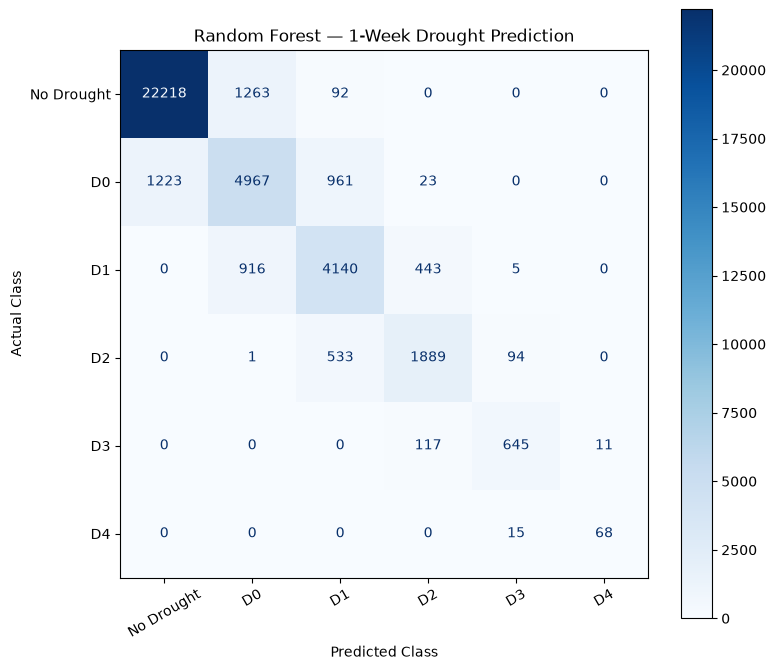

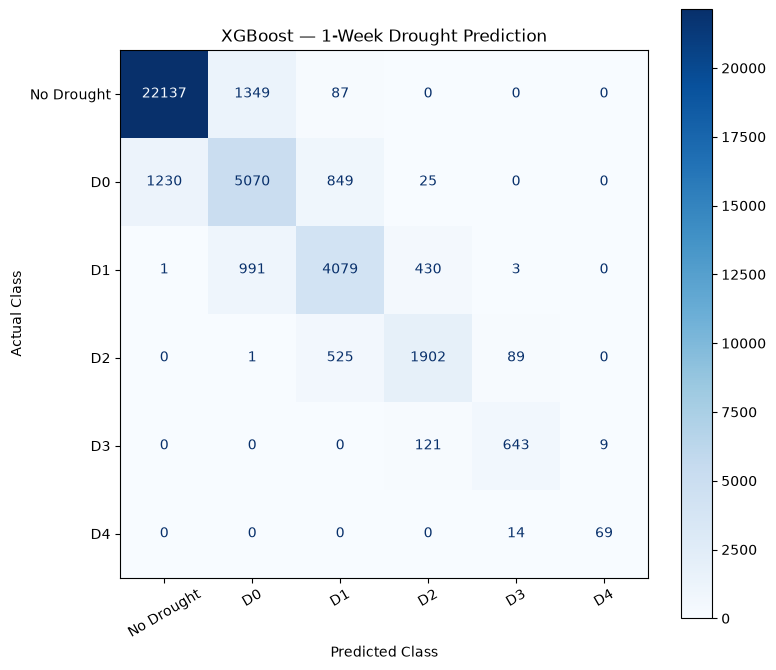

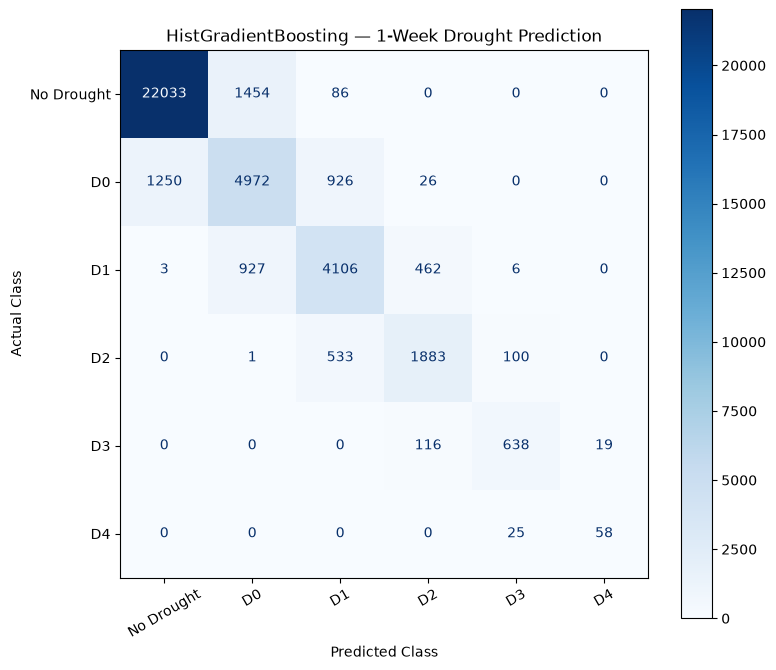

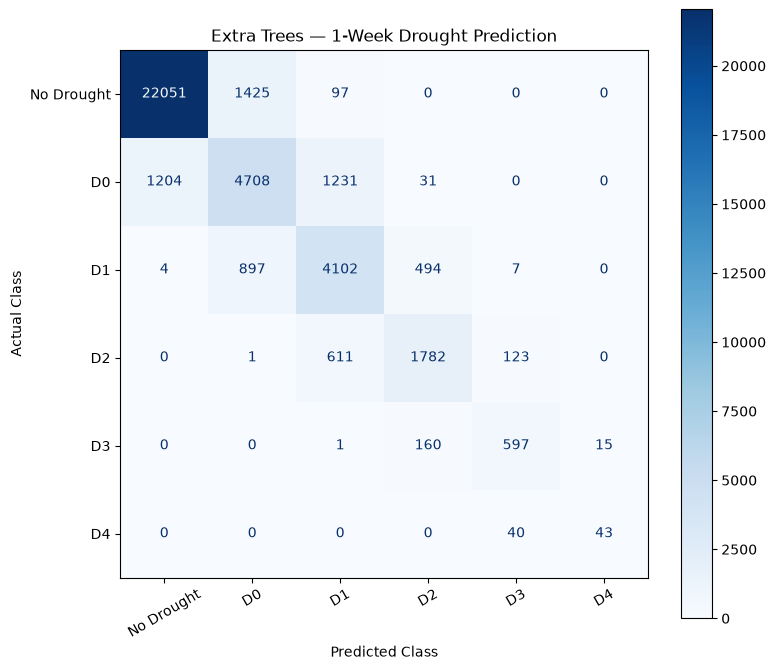

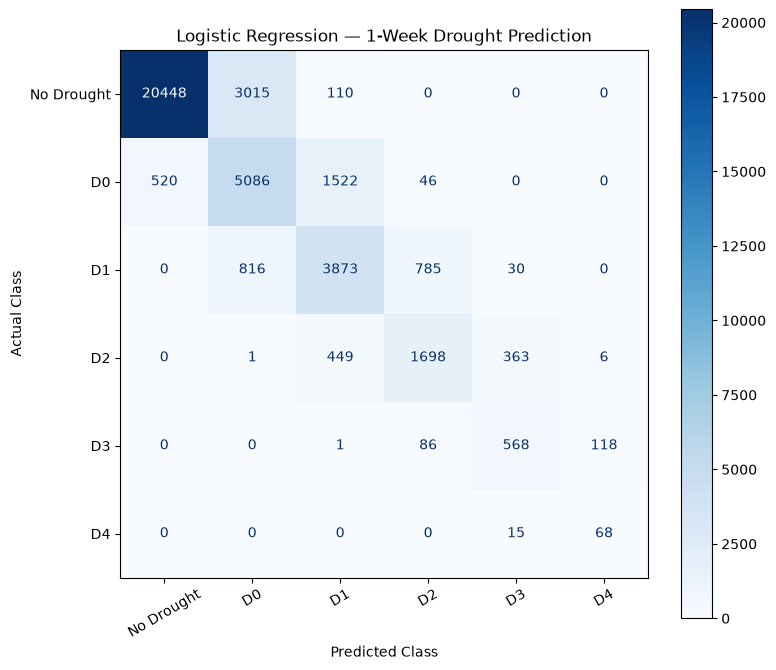

In [18]:
# ============================================================
# DROUGHTCAST — 1-WEEK CONFUSION MATRICES
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1-week test data
horizon = 1

X_test = datasets[horizon]["X_test"]
y_test = datasets[horizon]["y_test"]

# Already-trained models
models = {
    "Random Forest": rf_models[1],
    "XGBoost": xgb_models[1],
    "HistGradientBoosting": hgb_models[1],
    "Extra Trees": extra_models[1],
    "Logistic Regression": lr_models[1]
}

# Drought classes
classes = [0, 1, 2, 3, 4, 5]

class_names = [
    "No Drought",
    "D0",
    "D1",
    "D2",
    "D3",
    "D4"
]

# Generate confusion matrix
for name, model in models.items():

    pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        pred,
        labels=classes
    )

    fig, ax = plt.subplots(figsize=(8, 7))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=True
    )

    ax.set_title(
        f"{name} — 1-Week Drought Prediction"
    )

    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

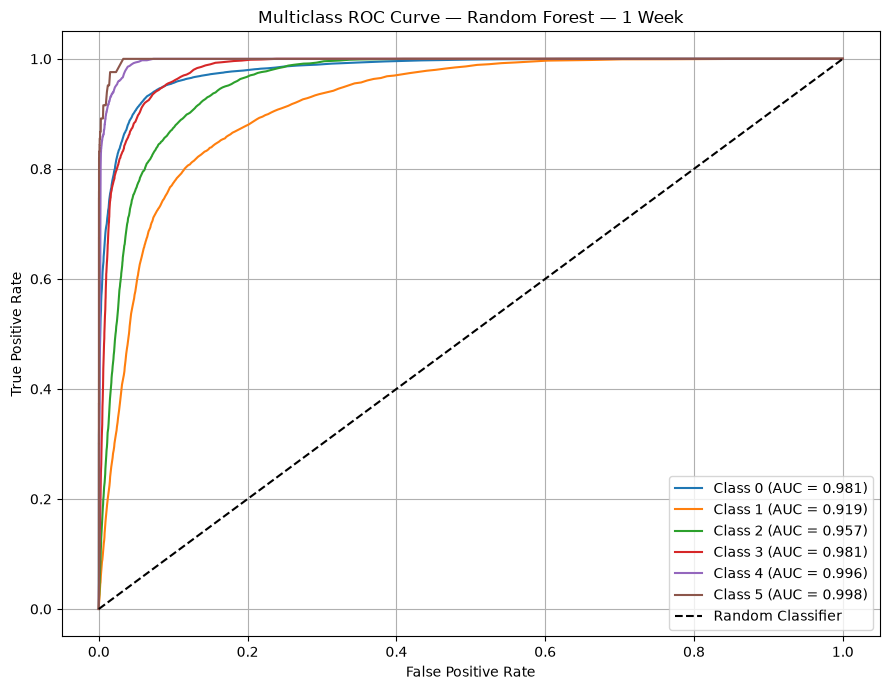

In [19]:
# ============================================================
# ROC CURVE — RANDOM FOREST — 1 WEEK
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

# ------------------------------------------------------------
# 1. Get 1-week test data
# ------------------------------------------------------------

X_test = datasets[1]["X_test"]
y_test = datasets[1]["y_test"]

model = rf_models[1]

# ------------------------------------------------------------
# 2. Convert classes to one-vs-rest format
# ------------------------------------------------------------

classes = [0, 1, 2, 3, 4, 5]

y_test_binary = label_binarize(
    y_test,
    classes=classes
)

# ------------------------------------------------------------
# 3. Get probability predictions
# ------------------------------------------------------------

y_prob = model.predict_proba(X_test)

# ------------------------------------------------------------
# 4. Plot ROC curves
# ------------------------------------------------------------

plt.figure(figsize=(9, 7))

for i in range(6):

    fpr, tpr, _ = roc_curve(
        y_test_binary[:, i],
        y_prob[:, i]
    )

    roc_auc = auc(
        fpr,
        tpr
    )

    plt.plot(
        fpr,
        tpr,
        label=f"Class {i} (AUC = {roc_auc:.3f})"
    )

# Random classifier
plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "Multiclass ROC Curve — Random Forest — 1 Week"
)

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

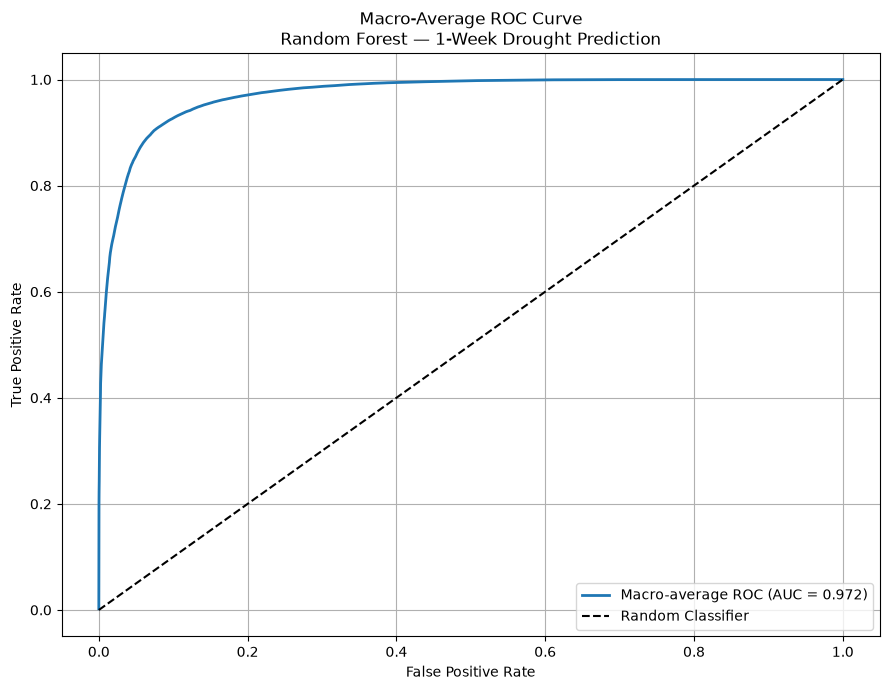

ROC RESULTS — RANDOM FOREST — 1 WEEK
Class 0 AUC : 0.9806
Class 1 AUC : 0.9189
Class 2 AUC : 0.9573
Class 3 AUC : 0.9812
Class 4 AUC : 0.9960
Class 5 AUC : 0.9983

Macro-Average AUC : 0.9720


In [21]:
# ============================================================
# MACRO-AVERAGE ROC CURVE
# RANDOM FOREST — 1 WEEK
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    roc_curve,
    auc,
    roc_auc_score
)

# ------------------------------------------------------------
# 1. GET 1-WEEK TEST DATA
# ------------------------------------------------------------

X_test = datasets[1]["X_test"]
y_test = datasets[1]["y_test"]

model = rf_models[1]

classes = [0, 1, 2, 3, 4, 5]

# ------------------------------------------------------------
# 2. CONVERT TARGET TO ONE-VS-REST FORMAT
# ------------------------------------------------------------

y_test_bin = label_binarize(
    y_test,
    classes=classes
)

# ------------------------------------------------------------
# 3. GET PREDICTED PROBABILITIES
# ------------------------------------------------------------

y_prob = model.predict_proba(X_test)

# ------------------------------------------------------------
# 4. CALCULATE ROC FOR EACH CLASS
# ------------------------------------------------------------

fpr = {}
tpr = {}
roc_auc = {}

for i in range(6):

    fpr[i], tpr[i], _ = roc_curve(
        y_test_bin[:, i],
        y_prob[:, i]
    )

    roc_auc[i] = auc(
        fpr[i],
        tpr[i]
    )

# ------------------------------------------------------------
# 5. CREATE MACRO-AVERAGE CURVE
# ------------------------------------------------------------

all_fpr = np.unique(
    np.concatenate(
        [fpr[i] for i in range(6)]
    )
)

mean_tpr = np.zeros_like(all_fpr)

for i in range(6):

    mean_tpr += np.interp(
        all_fpr,
        fpr[i],
        tpr[i]
    )

mean_tpr /= 6

macro_curve_auc = auc(
    all_fpr,
    mean_tpr
)

# ------------------------------------------------------------
# 6. OFFICIAL MULTICLASS MACRO AUC
# ------------------------------------------------------------

macro_auc = roc_auc_score(
    y_test,
    y_prob,
    labels=classes,
    multi_class="ovr",
    average="macro"
)

# ------------------------------------------------------------
# 7. PLOT
# ------------------------------------------------------------

plt.figure(figsize=(9, 7))

plt.plot(
    all_fpr,
    mean_tpr,
    linewidth=2,
    label=f"Macro-average ROC (AUC = {macro_auc:.3f})"
)

# Random classifier
plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title(
    "Macro-Average ROC Curve\n"
    "Random Forest — 1-Week Drought Prediction"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

# ------------------------------------------------------------
# 8. PRINT RESULTS
# ------------------------------------------------------------

print("=" * 60)
print("ROC RESULTS — RANDOM FOREST — 1 WEEK")
print("=" * 60)

for i in range(6):

    print(
        f"Class {i} AUC : {roc_auc[i]:.4f}"
    )

print(
    f"\nMacro-Average AUC : {macro_auc:.4f}"
)

In [ ]:
# ============================================================
# MACRO-AVERAGE ROC CURVE
# RANDOM FOREST — 1 WEEK
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    roc_curve,
    auc,
    roc_auc_score
)

# ------------------------------------------------------------
# 1. GET 1-WEEK TEST DATA
# ------------------------------------------------------------

X_test = datasets[1]["X_test"]
y_test = datasets[1]["y_test"]

model = rf_models[1]

classes = [0, 1, 2, 3, 4, 5]

# ------------------------------------------------------------
# 2. CONVERT TARGET TO ONE-VS-REST FORMAT
# ------------------------------------------------------------

y_test_bin = label_binarize(
    y_test,
    classes=classes
)

# ------------------------------------------------------------
# 3. GET PREDICTED PROBABILITIES
# ------------------------------------------------------------

y_prob = model.predict_proba(X_test)

# ------------------------------------------------------------
# 4. CALCULATE ROC FOR EACH CLASS
# ------------------------------------------------------------

fpr = {}
tpr = {}
roc_auc = {}

for i in range(6):

    fpr[i], tpr[i], _ = roc_curve(
        y_test_bin[:, i],
        y_prob[:, i]
    )

    roc_auc[i] = auc(
        fpr[i],
        tpr[i]
    )

# ------------------------------------------------------------
# 5. CREATE MACRO-AVERAGE CURVE
# ------------------------------------------------------------

all_fpr = np.unique(
    np.concatenate(
        [fpr[i] for i in range(6)]
    )
)

mean_tpr = np.zeros_like(all_fpr)

for i in range(6):

    mean_tpr += np.interp(
        all_fpr,
        fpr[i],
        tpr[i]
    )

mean_tpr /= 6

macro_curve_auc = auc(
    all_fpr,
    mean_tpr
)

# ------------------------------------------------------------
# 6. OFFICIAL MULTICLASS MACRO AUC
# ------------------------------------------------------------

macro_auc = roc_auc_score(
    y_test,
    y_prob,
    labels=classes,
    multi_class="ovr",
    average="macro"
)

# ------------------------------------------------------------
# 7. PLOT
# ------------------------------------------------------------

plt.figure(figsize=(9, 7))

plt.plot(
    all_fpr,
    mean_tpr,
    linewidth=2,
    label=f"Macro-average ROC (AUC = {macro_auc:.3f})"
)

# Random classifier
plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title(
    "Macro-Average ROC Curve\n"
    "Random Forest — 1-Week Drought Prediction"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

# ------------------------------------------------------------
# 8. PRINT RESULTS
# ------------------------------------------------------------

print("=" * 60)
print("ROC RESULTS — RANDOM FOREST — 1 WEEK")
print("=" * 60)

for i in range(6):

    print(
        f"Class {i} AUC : {roc_auc[i]:.4f}"
    )

print(
    f"\nMacro-Average AUC : {macro_auc:.4f}"
)

In [22]:
# ============================================================
# MACRO-AVERAGE ROC-AUC — RANDOM FOREST — ALL HORIZONS
# ============================================================

import numpy as np
import pandas as pd

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_auc_score


# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------

classes = [0, 1, 2, 3, 4, 5]

roc_results = []


# ------------------------------------------------------------
# CALCULATE ROC-AUC FOR EACH HORIZON
# ------------------------------------------------------------

for horizon in [1, 2, 3, 4]:

    print("=" * 65)
    print(f"RANDOM FOREST — {horizon}-WEEK ROC-AUC")
    print("=" * 65)

    # Test data
    X_test = datasets[horizon]["X_test"]
    y_test = datasets[horizon]["y_test"]

    # Already trained Random Forest
    model = rf_models[horizon]

    # Probability predictions
    y_prob = model.predict_proba(X_test)

    # Macro-average multiclass AUC
    macro_auc = roc_auc_score(
        y_test,
        y_prob,
        labels=classes,
        multi_class="ovr",
        average="macro"
    )

    print(f"Macro-Average AUC : {macro_auc:.4f}")

    roc_results.append({
        "Prediction Horizon": f"{horizon} Week",
        "Macro-Average AUC": macro_auc
    })


# ------------------------------------------------------------
# FINAL TABLE
# ------------------------------------------------------------

roc_results_df = pd.DataFrame(
    roc_results
)

print("\n")
print("=" * 65)
print("RANDOM FOREST — ROC-AUC COMPARISON")
print("=" * 65)

print(
    roc_results_df.to_string(
        index=False
    )
)

RANDOM FOREST — 1-WEEK ROC-AUC
Macro-Average AUC : 0.9720
RANDOM FOREST — 2-WEEK ROC-AUC
Macro-Average AUC : 0.9410
RANDOM FOREST — 3-WEEK ROC-AUC
Macro-Average AUC : 0.9118
RANDOM FOREST — 4-WEEK ROC-AUC
Macro-Average AUC : 0.8856


RANDOM FOREST — ROC-AUC COMPARISON
Prediction Horizon  Macro-Average AUC
            1 Week           0.972031
            2 Week           0.941024
            3 Week           0.911756
            4 Week           0.885596


In [28]:
# ============================================================
# RANDOM FOREST TUNING — DROUGHT PREDICTION
# 1, 2, 3, 4 WEEK HORIZONS
# ============================================================

import time
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score
)


# ============================================================
# PARAMETERS TO TRY
# ============================================================

parameter_sets = [

    {
        "n_estimators": 200,
        "max_depth": None,
        "min_samples_split": 2,
        "min_samples_leaf": 1
    },

    {
        "n_estimators": 300,
        "max_depth": None,
        "min_samples_split": 2,
        "min_samples_leaf": 1
    },

    {
        "n_estimators": 300,
        "max_depth": 20,
        "min_samples_split": 2,
        "min_samples_leaf": 1
    },

    {
        "n_estimators": 300,
        "max_depth": 30,
        "min_samples_split": 2,
        "min_samples_leaf": 1
    },

    {
        "n_estimators": 300,
        "max_depth": None,
        "min_samples_split": 5,
        "min_samples_leaf": 1
    },

    {
        "n_estimators": 300,
        "max_depth": None,
        "min_samples_split": 2,
        "min_samples_leaf": 2
    },

    {
        "n_estimators": 300,
        "max_depth": 20,
        "min_samples_split": 5,
        "min_samples_leaf": 2
    }
]


# ============================================================
# STORE BEST MODELS
# ============================================================

tuned_rf_models = {}

tuning_results = []


# ============================================================
# TUNE EACH PREDICTION HORIZON
# ============================================================

for horizon in [1, 2, 3, 4]:

    print("\n")
    print("=" * 75)
    print(f"TUNING RANDOM FOREST — {horizon}-WEEK DROUGHT PREDICTION")
    print("=" * 75)

    X_train = datasets[horizon]["X_train"]
    y_train = datasets[horizon]["y_train"].astype(int)

    X_val = datasets[horizon]["X_val"]
    y_val = datasets[horizon]["y_val"].astype(int)

    best_model = None
    best_params = None
    best_macro_f1 = -1

    # --------------------------------------------------------
    # Try parameter combinations
    # --------------------------------------------------------

    for number, params in enumerate(parameter_sets, start=1):

        print(f"\nTrying configuration {number}/{len(parameter_sets)}")
        print(params)

        start_time = time.time()

        model = RandomForestClassifier(
            n_estimators=params["n_estimators"],
            max_depth=params["max_depth"],
            min_samples_split=params["min_samples_split"],
            min_samples_leaf=params["min_samples_leaf"],
            max_features="sqrt",
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        )

        model.fit(
            X_train,
            y_train
        )

        val_pred = model.predict(X_val)

        accuracy = accuracy_score(
            y_val,
            val_pred
        )

        macro_f1 = f1_score(
            y_val,
            val_pred,
            average="macro",
            zero_division=0
        )

        weighted_f1 = f1_score(
            y_val,
            val_pred,
            average="weighted",
            zero_division=0
        )

        training_time = (
            time.time() - start_time
        ) / 60

        print(
            f"Accuracy   : {accuracy:.4f}"
        )

        print(
            f"Macro F1   : {macro_f1:.4f}"
        )

        print(
            f"Weighted F1: {weighted_f1:.4f}"
        )

        print(
            f"Time       : {training_time:.2f} min"
        )

        tuning_results.append({
            "Horizon": horizon,
            "Configuration": number,
            "Accuracy": accuracy,
            "Macro F1": macro_f1,
            "Weighted F1": weighted_f1,
            "Training Time": training_time,
            **params
        })

        # ----------------------------------------------------
        # Select based primarily on Macro F1
        # ----------------------------------------------------

        if macro_f1 > best_macro_f1:

            best_macro_f1 = macro_f1

            best_model = model

            best_params = params.copy()

    # --------------------------------------------------------
    # Save best model for this horizon
    # --------------------------------------------------------

    tuned_rf_models[horizon] = best_model

    print("\n")
    print("-" * 75)
    print(f"BEST RANDOM FOREST — {horizon} WEEK")
    print("-" * 75)

    print(
        f"Best Macro F1 : {best_macro_f1:.4f}"
    )

    print(
        "Best Parameters:"
    )

    print(best_params)


# ============================================================
# RESULTS TABLE
# ============================================================

results_df = pd.DataFrame(
    tuning_results
)

print("\n")
print("=" * 75)
print("RANDOM FOREST TUNING RESULTS")
print("=" * 75)

print(
    results_df.sort_values(
        ["Horizon", "Macro F1"],
        ascending=[True, False]
    ).to_string(index=False)
)



TUNING RANDOM FOREST — 1-WEEK DROUGHT PREDICTION

Trying configuration 1/7
{'n_estimators': 200, 'max_depth': None, 'min_samples_split': 2, 'min_samples_leaf': 1}
Accuracy   : 0.9000
Macro F1   : 0.7021
Weighted F1: 0.9002
Time       : 0.23 min

Trying configuration 2/7
{'n_estimators': 300, 'max_depth': None, 'min_samples_split': 2, 'min_samples_leaf': 1}
Accuracy   : 0.9011
Macro F1   : 0.7050
Weighted F1: 0.9012
Time       : 0.34 min

Trying configuration 3/7
{'n_estimators': 300, 'max_depth': 20, 'min_samples_split': 2, 'min_samples_leaf': 1}
Accuracy   : 0.8998
Macro F1   : 0.7201
Weighted F1: 0.9009
Time       : 0.31 min

Trying configuration 4/7
{'n_estimators': 300, 'max_depth': 30, 'min_samples_split': 2, 'min_samples_leaf': 1}
Accuracy   : 0.9010
Macro F1   : 0.7256
Weighted F1: 0.9012
Time       : 0.32 min

Trying configuration 5/7
{'n_estimators': 300, 'max_depth': None, 'min_samples_split': 5, 'min_samples_leaf': 1}
Accuracy   : 0.9006
Macro F1   : 0.7243
Weighted F1: 0.

In [5]:
# ============================================================
# BEST RANDOM FOREST CONFIGURATION FOR EACH HORIZON
# ============================================================

best_configs = (
    results_df
    .sort_values(
        ["Horizon", "Macro F1"],
        ascending=[True, False]
    )
    .groupby("Horizon")
    .first()
    .reset_index()
)

print("=" * 80)
print("BEST RANDOM FOREST CONFIGURATION — EACH HORIZON")
print("=" * 80)

print(
    best_configs[
        [
            "Horizon",
            "Accuracy",
            "Macro F1",
            "Weighted F1",
            "Training Time",
            "n_estimators",
            "max_depth",
            "min_samples_split",
            "min_samples_leaf"
        ]
    ].to_string(index=False)
)

NameError: name 'results_df' is not defined

In [9]:
# ============================================================
# FINAL TUNED RANDOM FOREST
# TRAIN + VALIDATION -> TEST
# ============================================================

import pandas as pd
import time

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)


# ============================================================
# BEST PARAMETERS FOUND FROM VALIDATION
# ============================================================

best_params = {

    1: {
        "n_estimators": 300,
        "max_depth": 20,
        "min_samples_split": 2,
        "min_samples_leaf": 2
    },

    2: {
        "n_estimators": 300,
        "max_depth": 20,
        "min_samples_split": 5,
        "min_samples_leaf": 2
    },

    3: {
        "n_estimators": 300,
        "max_depth": 20,
        "min_samples_split": 5,
        "min_samples_leaf": 2
    },

    4: {
        "n_estimators": 300,
        "max_depth": 20,
        "min_samples_split": 2,
        "min_samples_leaf": 1
    }
}


# ============================================================
# STORAGE
# ============================================================

final_rf_models = {}
final_results = []


# ============================================================
# FINAL TRAINING
# ============================================================

for horizon in [1, 2, 3, 4]:

    print("\n")
    print("=" * 75)
    print(f"FINAL RANDOM FOREST — {horizon}-WEEK DROUGHT PREDICTION")
    print("=" * 75)

    # --------------------------------------------------------
    # Get data
    # --------------------------------------------------------

    X_train = datasets[horizon]["X_train"]
    y_train = datasets[horizon]["y_train"].astype(int)

    X_val = datasets[horizon]["X_val"]
    y_val = datasets[horizon]["y_val"].astype(int)

    X_test = datasets[horizon]["X_test"]
    y_test = datasets[horizon]["y_test"].astype(int)

    # --------------------------------------------------------
    # Combine TRAIN + VALIDATION
    # --------------------------------------------------------

    X_train_final = pd.concat(
        [X_train, X_val],
        axis=0
    )

    y_train_final = pd.concat(
        [y_train, y_val],
        axis=0
    )

    print("Training rows:", len(X_train_final))
    print("Testing rows :", len(X_test))

    # --------------------------------------------------------
    # Parameters
    # --------------------------------------------------------

    params = best_params[horizon]

    print("\nParameters:")
    print(params)

    # --------------------------------------------------------
    # Train
    # --------------------------------------------------------

    start_time = time.time()

    rf = RandomForestClassifier(
        n_estimators=params["n_estimators"],
        max_depth=params["max_depth"],
        min_samples_split=params["min_samples_split"],
        min_samples_leaf=params["min_samples_leaf"],
        max_features="sqrt",
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    )

    rf.fit(
        X_train_final,
        y_train_final
    )

    training_time = (
        time.time() - start_time
    ) / 60

    final_rf_models[horizon] = rf

    # --------------------------------------------------------
    # TEST PREDICTION
    # --------------------------------------------------------

    test_pred = rf.predict(X_test)

    # --------------------------------------------------------
    # METRICS
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_test,
        test_pred
    )

    macro_f1 = f1_score(
        y_test,
        test_pred,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_test,
        test_pred,
        average="weighted",
        zero_division=0
    )

    # --------------------------------------------------------
    # PRINT RESULTS
    # --------------------------------------------------------

    print("\nFINAL TEST RESULTS")
    print("-" * 50)

    print(
        f"Accuracy     : {accuracy:.4f}"
    )

    print(
        f"Macro F1     : {macro_f1:.4f}"
    )

    print(
        f"Weighted F1  : {weighted_f1:.4f}"
    )

    print(
        f"Training Time: {training_time:.2f} min"
    )

    # --------------------------------------------------------
    # Classification report
    # --------------------------------------------------------

    print("\nClassification Report:")

    print(
        classification_report(
            y_test,
            test_pred,
            labels=[0, 1, 2, 3, 4, 5],
            target_names=[
                "No Drought",
                "D0",
                "D1",
                "D2",
                "D3",
                "D4"
            ],
            zero_division=0
        )
    )

    # --------------------------------------------------------
    # Store result
    # --------------------------------------------------------

    final_results.append({
        "Horizon": horizon,
        "Accuracy": accuracy,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1,
        "Training Time": training_time
    })


# ============================================================
# FINAL COMPARISON
# ============================================================

final_results_df = pd.DataFrame(
    final_results
)

print("\n")
print("=" * 75)
print("FINAL RANDOM FOREST TEST RESULTS")
print("=" * 75)

print(
    final_results_df.round(4).to_string(index=False)
)



FINAL RANDOM FOREST — 1-WEEK DROUGHT PREDICTION
Training rows: 238506
Testing rows : 39624

Parameters:
{'n_estimators': 300, 'max_depth': 20, 'min_samples_split': 2, 'min_samples_leaf': 2}

FINAL TEST RESULTS
--------------------------------------------------
Accuracy     : 0.8583
Macro F1     : 0.8038
Weighted F1  : 0.8598
Training Time: 0.52 min

Classification Report:
              precision    recall  f1-score   support

  No Drought       0.96      0.94      0.95     23573
          D0       0.69      0.73      0.71      7174
          D1       0.73      0.75      0.74      5504
          D2       0.76      0.76      0.76      2517
          D3       0.84      0.83      0.84       773
          D4       0.83      0.83      0.83        83

    accuracy                           0.86     39624
   macro avg       0.80      0.81      0.80     39624
weighted avg       0.86      0.86      0.86     39624



FINAL RANDOM FOREST — 2-WEEK DROUGHT PREDICTION
Training rows: 238506
Testing 

In [31]:
# ============================================================
# SAVE FINAL TUNED RANDOM FOREST MODELS
# ============================================================

import joblib
import os

# Create folder
os.makedirs("saved_models", exist_ok=True)

for horizon in [1, 2, 3, 4]:

    filename = f"saved_models/random_forest_{horizon}week.pkl"

    joblib.dump(
        final_rf_models[horizon],
        filename
    )

    print(f"Saved: {filename}")

print("\nAll final Random Forest models saved successfully.")

Saved: saved_models/random_forest_1week.pkl
Saved: saved_models/random_forest_2week.pkl
Saved: saved_models/random_forest_3week.pkl
Saved: saved_models/random_forest_4week.pkl

All final Random Forest models saved successfully.


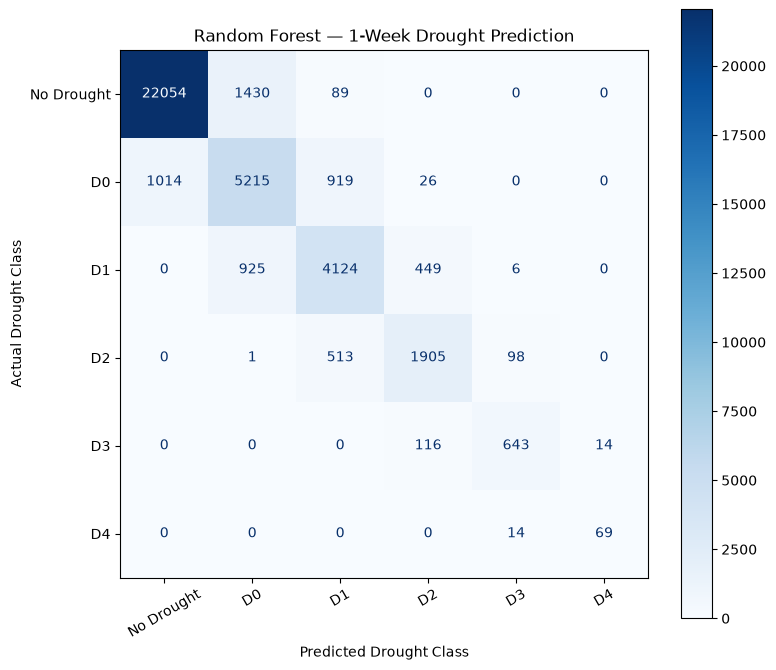


1-WEEK CONFUSION MATRIX
[[22054  1430    89     0     0     0]
 [ 1014  5215   919    26     0     0]
 [    0   925  4124   449     6     0]
 [    0     1   513  1905    98     0]
 [    0     0     0   116   643    14]
 [    0     0     0     0    14    69]]


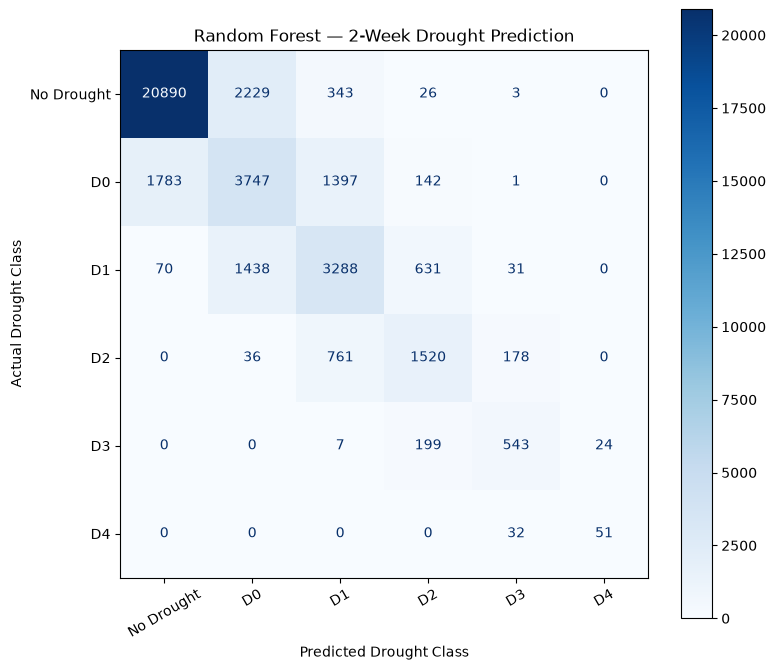


2-WEEK CONFUSION MATRIX
[[20890  2229   343    26     3     0]
 [ 1783  3747  1397   142     1     0]
 [   70  1438  3288   631    31     0]
 [    0    36   761  1520   178     0]
 [    0     0     7   199   543    24]
 [    0     0     0     0    32    51]]


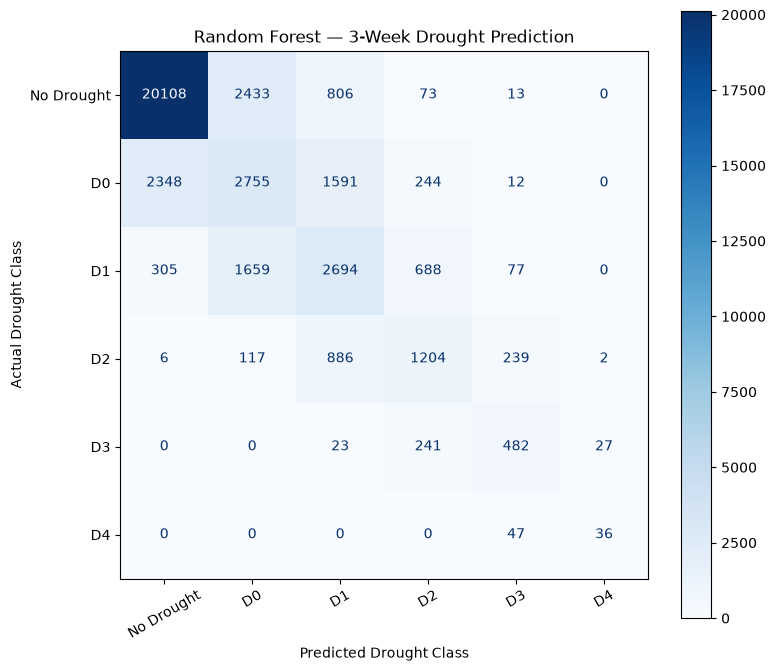


3-WEEK CONFUSION MATRIX
[[20108  2433   806    73    13     0]
 [ 2348  2755  1591   244    12     0]
 [  305  1659  2694   688    77     0]
 [    6   117   886  1204   239     2]
 [    0     0    23   241   482    27]
 [    0     0     0     0    47    36]]


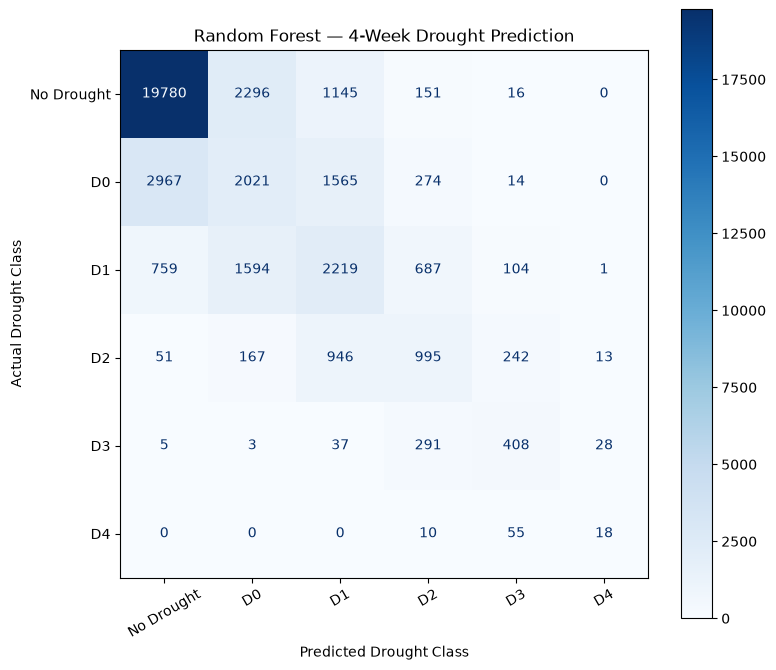


4-WEEK CONFUSION MATRIX
[[19780  2296  1145   151    16     0]
 [ 2967  2021  1565   274    14     0]
 [  759  1594  2219   687   104     1]
 [   51   167   946   995   242    13]
 [    5     3    37   291   408    28]
 [    0     0     0    10    55    18]]


In [32]:
# ============================================================
# FINAL RANDOM FOREST — CONFUSION MATRICES
# ALL 4 DROUGHT PREDICTION HORIZONS
# ============================================================

import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

classes = [0, 1, 2, 3, 4, 5]

class_names = [
    "No Drought",
    "D0",
    "D1",
    "D2",
    "D3",
    "D4"
]

for horizon in [1, 2, 3, 4]:

    # Final untouched test data
    X_test = datasets[horizon]["X_test"]
    y_test = datasets[horizon]["y_test"].astype(int)

    # Final tuned model
    model = final_rf_models[horizon]

    # Prediction
    y_pred = model.predict(X_test)

    # Confusion matrix
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=classes
    )

    # Plot
    fig, ax = plt.subplots(figsize=(8, 7))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    disp.plot(
        ax=ax,
        values_format="d",
        cmap="Blues"
    )

    ax.set_title(
        f"Random Forest — {horizon}-Week Drought Prediction"
    )

    ax.set_xlabel("Predicted Drought Class")
    ax.set_ylabel("Actual Drought Class")

    plt.xticks(rotation=30)

    plt.tight_layout()
    plt.show()

    print(f"\n{horizon}-WEEK CONFUSION MATRIX")
    print(cm)

In [10]:
# ============================================================
# FINAL TEST ROC-AUC
# USING final_rf_models DIRECTLY
# ============================================================

import numpy as np
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

classes = [0, 1, 2, 3, 4, 5]

print("=" * 70)
print("FINAL RANDOM FOREST — TEST ROC-AUC")
print("=" * 70)

final_auc_results = {}

for horizon in [1, 2, 3, 4]:

    # Test data
    X_test = datasets[horizon]["X_test"]
    y_test = datasets[horizon]["y_test"].astype(int)

    # Final trained model already in memory
    model = final_rf_models[horizon]

    # Probability prediction
    y_prob = model.predict_proba(X_test)

    # Convert to one-vs-rest
    y_test_bin = label_binarize(
        y_test,
        classes=classes
    )

    fpr = {}
    tpr = {}
    class_auc = {}

    # ROC for each drought class
    for i in range(6):

        fpr[i], tpr[i], _ = roc_curve(
            y_test_bin[:, i],
            y_prob[:, i]
        )

        class_auc[i] = auc(
            fpr[i],
            tpr[i]
        )

    # Common FPR points
    all_fpr = np.unique(
        np.concatenate(
            [fpr[i] for i in range(6)]
        )
    )

    # Macro-average TPR
    mean_tpr = np.zeros_like(all_fpr)

    for i in range(6):

        mean_tpr += np.interp(
            all_fpr,
            fpr[i],
            tpr[i]
        )

    mean_tpr /= 6

    # Macro-average AUC
    macro_auc = auc(
        all_fpr,
        mean_tpr
    )

    final_auc_results[horizon] = macro_auc

    print(
        f"{horizon}-Week Macro-Average AUC : "
        f"{macro_auc:.4f}"
    )

print("=" * 70)

FINAL RANDOM FOREST — TEST ROC-AUC
1-Week Macro-Average AUC : 0.9729
2-Week Macro-Average AUC : 0.9432
3-Week Macro-Average AUC : 0.9143
4-Week Macro-Average AUC : 0.8890


1-Week Macro-Average AUC : 0.9729
2-Week Macro-Average AUC : 0.9432
3-Week Macro-Average AUC : 0.9143
4-Week Macro-Average AUC : 0.8890


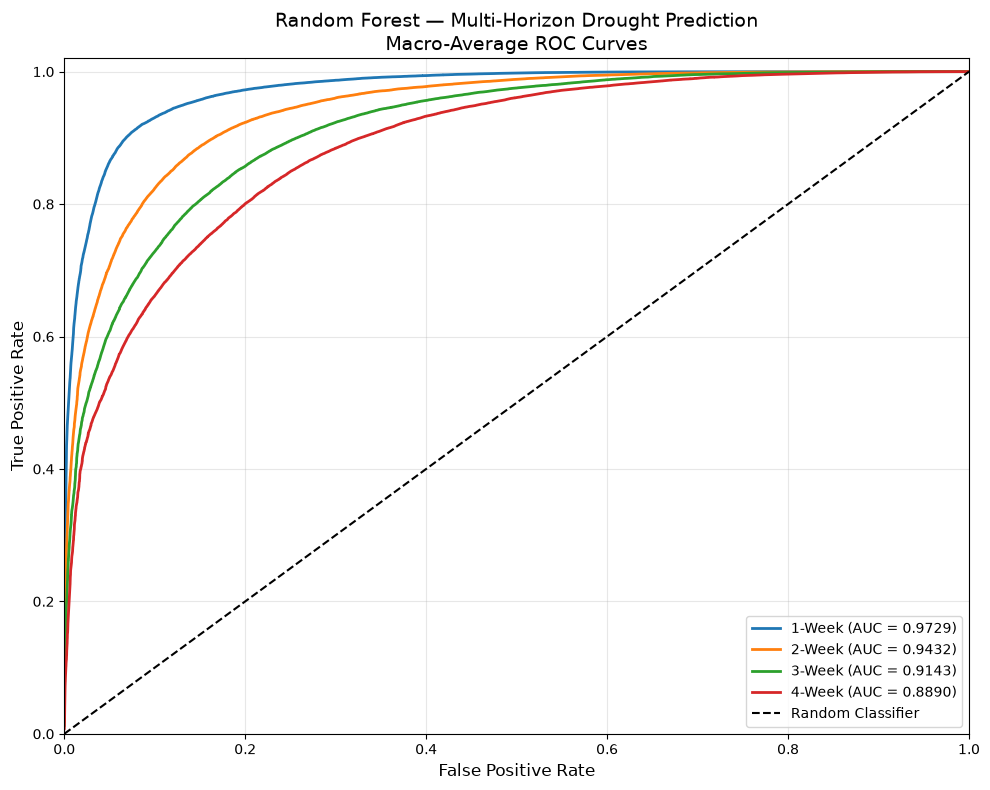

In [11]:
# ============================================================
# FINAL RANDOM FOREST — 4 ROC CURVES IN ONE GRAPH
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

classes = [0, 1, 2, 3, 4, 5]

plt.figure(figsize=(10, 8))

for horizon in [1, 2, 3, 4]:

    # --------------------------------------------------------
    # Test data
    # --------------------------------------------------------

    X_test = datasets[horizon]["X_test"]
    y_test = datasets[horizon]["y_test"].astype(int)

    # Final tuned model
    model = final_rf_models[horizon]

    # --------------------------------------------------------
    # Probability predictions
    # --------------------------------------------------------

    y_prob = model.predict_proba(X_test)

    # One-vs-rest labels
    y_test_bin = label_binarize(
        y_test,
        classes=classes
    )

    # --------------------------------------------------------
    # ROC for each class
    # --------------------------------------------------------

    fpr = {}
    tpr = {}

    for i in range(6):

        fpr[i], tpr[i], _ = roc_curve(
            y_test_bin[:, i],
            y_prob[:, i]
        )

    # --------------------------------------------------------
    # Common FPR points
    # --------------------------------------------------------

    all_fpr = np.unique(
        np.concatenate(
            [fpr[i] for i in range(6)]
        )
    )

    # --------------------------------------------------------
    # Macro-average TPR
    # --------------------------------------------------------

    mean_tpr = np.zeros_like(all_fpr)

    for i in range(6):

        mean_tpr += np.interp(
            all_fpr,
            fpr[i],
            tpr[i]
        )

    mean_tpr /= 6

    # --------------------------------------------------------
    # Macro AUC
    # --------------------------------------------------------

    macro_auc = auc(
        all_fpr,
        mean_tpr
    )

    # --------------------------------------------------------
    # Plot
    # --------------------------------------------------------

    plt.plot(
        all_fpr,
        mean_tpr,
        linewidth=2,
        label=f"{horizon}-Week (AUC = {macro_auc:.4f})"
    )

    print(
        f"{horizon}-Week Macro-Average AUC : "
        f"{macro_auc:.4f}"
    )


# ============================================================
# RANDOM CLASSIFIER
# ============================================================

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    linewidth=1.5,
    label="Random Classifier"
)


# ============================================================
# GRAPH SETTINGS
# ============================================================

plt.xlabel("False Positive Rate", fontsize=12)

plt.ylabel("True Positive Rate", fontsize=12)

plt.title(
    "Random Forest — Multi-Horizon Drought Prediction\n"
    "Macro-Average ROC Curves",
    fontsize=14
)

plt.xlim(0, 1)
plt.ylim(0, 1.02)

plt.grid(
    True,
    alpha=0.3
)

plt.legend(
    loc="lower right"
)

plt.tight_layout()

plt.show()